# Caso de estudio Cyclistic: ¿cómo usan las bicicletas los miembros y los ciclistas casuales?

**Certificado Profesional de Google Data Analytics · Proyecto final (caso 1)**

- **Herramientas:** SQL (DuckDB) para cargar, limpiar y agregar; Python (pandas, matplotlib) para revisar y graficar.
- **Datos:** viajes de Divvy (Chicago), noviembre 2025 a octubre 2026.
- **Scripts SQL:** `sql/01_carga.sql`, `sql/02_limpieza.sql` y `sql/03_analisis.sql`.

El notebook sigue las fases del proceso de análisis: **Ask → Prepare → Process → Analyze → Share → Act**.

## 1. Ask: la tarea de negocio

La directora de Marketing, Lily Moreno, quiere convertir ciclistas casuales en miembros anuales, porque los miembros
son más rentables. La pregunta asignada es: **¿en qué se diferencia el uso de las bicicletas entre miembros anuales
y ciclistas casuales?**

Partes interesadas: Lily Moreno (Marketing), el equipo ejecutivo de Cyclistic (aprueba la propuesta) y el equipo
de análisis de Marketing.

## 2. Prepare: los datos

### 2.1 Configuración

In [1]:
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import pandas as pd
from IPython.display import display

pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 160)

# Carpetas del proyecto
CARPETA_DATOS = Path('datos_originales')
CARPETA_SQL = Path('sql')
CARPETA_GRAFICOS = Path('graficos')
CARPETA_RESUMEN = Path('resumen')
for carpeta in (CARPETA_GRAFICOS, CARPETA_RESUMEN):
    carpeta.mkdir(exist_ok=True)

ARCHIVOS = sorted(CARPETA_DATOS.glob('*-divvy-tripdata.csv'))
if len(ARCHIVOS) != 12:
    raise FileNotFoundError(
        f'Se esperaban 12 archivos CSV en {CARPETA_DATOS}/ y hay {len(ARCHIVOS)}. '
        'Revisa el README para descargarlos.'
    )

# Base de datos DuckDB en un archivo local (no se sube a GitHub, ver .gitignore)
con = duckdb.connect('cyclistic.duckdb')


def sql(consulta: str) -> pd.DataFrame:
    """Ejecuta una consulta SQL y devuelve el resultado como DataFrame."""
    return con.sql(consulta).df()


def ejecutar_script(nombre: str) -> None:
    """Ejecuta un archivo .sql completo de la carpeta sql/."""
    con.execute((CARPETA_SQL / nombre).read_text(encoding='utf-8'))


def fmt_num(valor: float) -> str:
    """Número entero con punto de miles: 49971 -> '49.971'."""
    return f'{valor:,.0f}'.replace(',', '.')


def fmt_dec(valor: float, decimales: int = 1) -> str:
    """Número con coma decimal: 4.42 -> '4,4'."""
    return f'{valor:.{decimales}f}'.replace('.', ',')


def guardar_grafico(fig: plt.Figure, nombre: str) -> None:
    """Ajusta márgenes, guarda el gráfico en graficos/ y lo muestra."""
    fig.tight_layout()
    fig.savefig(CARPETA_GRAFICOS / nombre, dpi=150)
    plt.show()


# Colores consistentes en todos los gráficos: casuales en azul, miembros en gris
AZUL, GRIS = '#2a6fdb', '#b9b9ae'
COLORES = {'casual': AZUL, 'member': GRIS}
ETIQUETAS = {'casual': 'Casuales', 'member': 'Miembros'}
TIPOS = ['casual', 'member']
DIAS = {1: 'Dom', 2: 'Lun', 3: 'Mar', 4: 'Mié', 5: 'Jue', 6: 'Vie', 7: 'Sáb'}
MESES = ['ene', 'feb', 'mar', 'abr', 'may', 'jun', 'jul', 'ago', 'sep', 'oct', 'nov', 'dic']

plt.rcParams.update({
    'figure.dpi': 110,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.titleweight': 'bold',
    'axes.titlesize': 12,
})
formato_miles = mticker.FuncFormatter(lambda x, _: f'{fmt_num(x / 1000)} mil' if x else '0')
formato_pct = mticker.PercentFormatter(decimals=0)

### 2.2 Archivos

Son 12 archivos CSV mensuales descargados de [divvy-tripdata](https://divvy-tripdata.s3.amazonaws.com/index.html),
publicados por Lyft Bikes and Scooters (Divvy) bajo su
[licencia de datos](https://www.divvybikes.com/data-license-agreement).

Nota: el ZIP de enero de 2026 traía un CSV llamado `202501-divvy-tripdata.csv`. Las fechas internas son de enero
de 2026, así que se renombró a `202601-divvy-tripdata.csv`. El archivo de octubre de 2025 se dejó fuera para
trabajar con 12 meses exactos.

In [2]:
pd.DataFrame({
    'archivo': [a.name for a in ARCHIVOS],
    'tamaño_MB': [round(a.stat().st_size / 1e6, 1) for a in ARCHIVOS],
})

,archivo,tamaño_MB
0,202511-divvy-tripdata.csv,71.1
1,202512-divvy-tripdata.csv,28.3
2,202601-divvy-tripdata.csv,27.9
3,202602-divvy-tripdata.csv,41.2
4,202603-divvy-tripdata.csv,64.0
5,202604-divvy-tripdata.csv,89.8
6,202605-divvy-tripdata.csv,130.7
7,202606-divvy-tripdata.csv,152.6
8,202607-divvy-tripdata.csv,173.1
9,202608-divvy-tripdata.csv,172.8


### 2.3 Carga y estructura de los datos en bruto (`sql/01_carga.sql`)

In [3]:
print((CARPETA_SQL / '01_carga.sql').read_text(encoding='utf-8'))
ejecutar_script('01_carga.sql')

-- =====================================================================
-- Caso de estudio Cyclistic (Google Data Analytics)
-- 01 - Carga de los datos en bruto
-- Motor: DuckDB
-- Entrada: los 12 CSV mensuales de Divvy en la carpeta datos_originales/
-- Salida:  tabla viajes_raw (una fila por viaje, sin modificar)
-- =====================================================================

-- union_by_name alinea las columnas por nombre aunque cambie su orden
-- entre archivos. La columna `archivo` guarda el mes de origen (AAAAMM)
-- para poder revisar cada archivo por separado.
CREATE OR REPLACE TABLE viajes_raw AS
SELECT
    * EXCLUDE (filename),
    REGEXP_EXTRACT(filename, '(\d{6})-divvy-tripdata', 1) AS archivo
FROM READ_CSV('datos_originales/*-divvy-tripdata.csv',
              union_by_name = TRUE,
              filename = TRUE);



In [4]:
# Filas y rango de fechas de cada archivo: confirma que cada archivo corresponde a su mes
sql('''
SELECT archivo, COUNT(*) AS filas, MIN(started_at) AS primer_inicio, MAX(started_at) AS ultimo_inicio
FROM viajes_raw
GROUP BY archivo
ORDER BY archivo
''')

,archivo,filas,primer_inicio,ultimo_inicio
0,202511,356628,2025-10-31 01:24:38.549,2025-11-30 23:51:43.800
1,202512,140534,2025-11-30 16:02:08.178,2025-12-31 23:53:24.274
2,202601,137787,2025-12-31 10:30:49.482,2026-01-31 23:56:54.069
3,202602,201450,2026-01-31 11:08:07.830,2026-02-28 23:57:54.093
4,202603,317037,2026-02-28 10:48:22.074,2026-03-31 23:55:56.848
5,202604,448252,2026-04-01 00:01:42.066,2026-04-30 23:58:56.151
6,202605,653704,2026-04-30 00:24:47.685,2026-05-31 23:57:08.778
7,202606,762550,2026-05-31 01:07:54.969,2026-06-30 23:58:47.113
8,202607,869051,2026-06-29 23:11:19.957,2026-07-31 23:58:05.898
9,202608,868191,2026-07-30 23:01:41.716,2026-08-31 23:55:36.979


In [5]:
sql('DESCRIBE viajes_raw')[['column_name', 'column_type']]

,column_name,column_type
0,ride_id,VARCHAR
1,rideable_type,VARCHAR
2,started_at,TIMESTAMP
3,ended_at,TIMESTAMP
4,start_station_name,VARCHAR
5,start_station_id,VARCHAR
6,end_station_name,VARCHAR
7,end_station_id,VARCHAR
8,start_lat,DOUBLE
9,start_lng,DOUBLE


In [6]:
sql('SELECT * FROM viajes_raw LIMIT 5')

,ride_id,rideable_type,started_at,ended_at,start_station_name,start_station_id,end_station_name,end_station_id,start_lat,start_lng,end_lat,end_lng,member_casual,archivo
0,E555D9F8E9C2F56B,electric_bike,2025-11-04 00:09:07.792,2025-11-04 00:15:04.661,None,None,None,None,41.94,-87.67,41.94,-87.67,casual,202511
1,EAEBE70DBF015886,electric_bike,2025-11-04 14:32:09.067,2025-11-04 14:36:43.998,None,None,None,None,41.90,-87.64,41.91,-87.64,casual,202511
2,A42F8404F804E56E,electric_bike,2025-11-04 12:20:48.215,2025-11-04 12:21:01.630,None,None,None,None,41.89,-87.63,41.89,-87.63,casual,202511
3,E49D01E38A1E074E,electric_bike,2025-11-04 12:17:16.548,2025-11-04 12:17:51.527,None,None,None,None,41.89,-87.63,41.89,-87.63,casual,202511
4,9308F609195D2414,electric_bike,2025-11-04 08:16:27.979,2025-11-04 08:21:02.780,None,None,None,None,41.89,-87.64,41.88,-87.64,casual,202511


### 2.4 Calidad de los datos en bruto

In [7]:
calidad = sql('''
SELECT
    COUNT(*)                                                        AS filas,
    COUNT(*) - COUNT(DISTINCT ride_id)                              AS ride_id_duplicados,
    COUNT(*) FILTER (WHERE start_station_name IS NULL)              AS sin_estacion_inicio,
    COUNT(*) FILTER (WHERE end_station_name IS NULL)                AS sin_estacion_fin,
    COUNT(*) FILTER (WHERE start_station_name <> TRIM(start_station_name)
                        OR end_station_name <> TRIM(end_station_name)) AS estacion_con_espacios,
    COUNT(*) FILTER (WHERE end_lat IS NULL)                         AS sin_coordenadas_fin,
    COUNT(*) FILTER (WHERE ended_at <= started_at)                  AS duracion_cero_o_negativa,
    COUNT(*) FILTER (WHERE ended_at - started_at < INTERVAL 60 SECOND) AS menos_de_60_seg,
    COUNT(*) FILTER (WHERE ended_at - started_at > INTERVAL 24 HOUR)   AS mas_de_24_horas
FROM viajes_raw
''')
calidad.T.rename(columns={0: 'cantidad'})

,cantidad
filas,6294451
ride_id_duplicados,35
sin_estacion_inicio,1301806
sin_estacion_fin,1367998
estacion_con_espacios,68414
sin_coordenadas_fin,5303
duracion_cero_o_negativa,29
menos_de_60_seg,159672
mas_de_24_horas,5155


In [8]:
# Valores posibles de las columnas categóricas
sql('''
SELECT rideable_type, member_casual, COUNT(*) AS viajes
FROM viajes_raw
GROUP BY rideable_type, member_casual
ORDER BY rideable_type, member_casual
''')

,rideable_type,member_casual,viajes
0,classic_bike,casual,536098
1,classic_bike,member,1223157
2,electric_bike,casual,1703315
3,electric_bike,member,2831881


In [9]:
# Estaciones de prueba o bodega: no son viajes de clientes
sql('''
SELECT start_station_name, COUNT(*) AS viajes
FROM viajes_raw
WHERE start_station_name ILIKE '%test%' OR start_station_name ILIKE '%warehouse%'
GROUP BY start_station_name
ORDER BY viajes DESC
''')

,start_station_name,viajes
0,STAFF & VISITORS @ West Chicago Warehouse,17
1,Hastings Test Station,11


**¿Cumplen ROCCC?** Son confiables y originales (registros del propio operador, sin muestreo), actuales (los 12 meses
más recientes) y citados (licencia pública). Son *parcialmente* completos: faltan las estaciones en ~20% de los
viajes y no hay información de los usuarios.

**Privacidad:** no hay datos personales. Por eso no se puede contar personas distintas ni saber si un casual vive
en Chicago.

## 3. Process: limpieza y transformación (`sql/02_limpieza.sql`)

El script clasifica cada viaje con el **primer** motivo de exclusión que cumple, en este orden:

1. Datos incompletos (sin ID, fechas o tipo de usuario).
2. `ride_id` duplicado (el mismo viaje en dos archivos mensuales).
3. Inicio fuera del periodo 2025-11-01 a 2026-10-31.
4. Duración menor a 60 segundos (falsos inicios).
5. Duración mayor a 24 horas (bicicletas perdidas o no devueltas).
6. Inicio o fin en una estación de prueba o bodega.

Además, quita los espacios sobrantes de los nombres de estación. Los viajes **sin** nombre de estación se conservan
(casi todos son bicicletas eléctricas estacionadas fuera de una estación) y solo se excluyen del análisis por
estación.

Columnas nuevas: `ride_length_min`, `day_of_week` (1 = domingo … 7 = sábado), `hora`, `mes`, `tipo_dia`,
`estacion_anio`, `franja_horaria`, `distancia_km` (haversine) e `ida_y_vuelta` (NULL si falta alguna estación).

In [10]:
print((CARPETA_SQL / '02_limpieza.sql').read_text(encoding='utf-8'))
ejecutar_script('02_limpieza.sql')

-- =====================================================================
-- Caso de estudio Cyclistic (Google Data Analytics)
-- 02 - Limpieza y transformación
-- Entrada: tabla viajes_raw (creada por 01_carga.sql)
-- Salida:  vista viajes_clasificados (cada viaje con su motivo de exclusión)
--          tabla viajes (solo los viajes válidos, con columnas nuevas)
-- =====================================================================

-- Distancia en línea recta entre dos coordenadas (fórmula de haversine), en km
CREATE OR REPLACE MACRO haversine_km(lat1, lng1, lat2, lng2) AS
    2 * 6371 * ASIN(SQRT(
        POWER(SIN(RADIANS(lat2 - lat1) / 2), 2)
        + COS(RADIANS(lat1)) * COS(RADIANS(lat2))
        * POWER(SIN(RADIANS(lng2 - lng1) / 2), 2)
    ));

-- 1) CLASIFICACIÓN
--    Cada viaje recibe el PRIMER motivo de exclusión que cumple, en este orden.
--    Los viajes con motivo NULL son válidos. Así las reglas existen en un
--    solo lugar y el conteo de filas eliminadas sale de l

In [11]:
# Filas eliminadas por cada regla (sale de la misma clasificación que usa la limpieza)
embudo = sql('''
SELECT COALESCE(motivo_exclusion, '7. Conservado') AS resultado, COUNT(*) AS filas
FROM viajes_clasificados
GROUP BY resultado
ORDER BY resultado
''')
total_bruto = embudo['filas'].sum()
eliminadas = total_bruto - embudo.loc[embudo['resultado'] == '7. Conservado', 'filas'].item()
print(f'Eliminadas en total: {fmt_num(eliminadas)} de {fmt_num(total_bruto)} filas '
      f'({fmt_dec(100 * eliminadas / total_bruto)}%)')
embudo

Eliminadas en total: 165.026 de 6.294.451 filas (2,6%)


,resultado,filas
0,2. ride_id duplicado,35
1,3. Fuera del periodo,128
2,4. Menos de 60 segundos,159672
3,5. Más de 24 horas,5128
4,6. Estación de prueba o bodega,63
5,7. Conservado,6129425


In [12]:
# Verificación de la tabla limpia
sql('''
SELECT
    COUNT(*)                                                   AS viajes,
    COUNT(DISTINCT ride_id)                                    AS ids_unicos,
    MIN(started_at)                                            AS primer_viaje,
    MAX(started_at)                                            AS ultimo_viaje,
    MIN(ride_length_min)                                       AS dur_min,
    MAX(ride_length_min)                                       AS dur_max,
    ROUND(100.0 * AVG((start_station_name IS NULL)::INT), 1)   AS pct_sin_estacion
FROM viajes
''')

,viajes,ids_unicos,primer_viaje,ultimo_viaje,dur_min,dur_max,pct_sin_estacion
0,6129425,6129425,2025-11-01 00:00:08.613,2026-10-31 23:59:45.105,1.0,1439.95505,19.8


## 4. Analyze: miembros vs. casuales

Las consultas de esta sección también están en `sql/03_analisis.sql`.

### 4.1 Cálculos que pide el curso
Promedio y máximo de `ride_length`, y moda de `day_of_week` (1 = domingo … 7 = sábado).

In [13]:
sql('''
SELECT
    'Todos' AS member_casual,
    ROUND(AVG(ride_length_min), 1) AS ride_length_promedio_min,
    ROUND(MAX(ride_length_min), 1) AS ride_length_max_min,
    MODE(day_of_week)              AS day_of_week_moda
FROM viajes
UNION ALL
SELECT
    member_casual,
    ROUND(AVG(ride_length_min), 1),
    ROUND(MAX(ride_length_min), 1),
    MODE(day_of_week)
FROM viajes
GROUP BY member_casual
''')

,member_casual,ride_length_promedio_min,ride_length_max_min,day_of_week_moda
0,Todos,14.2,1440.0,7
1,member,12.1,1439.9,3
2,casual,18.0,1440.0,7


### 4.2 Tablas dinámicas (equivalentes a las del curso, hechas con pandas)

In [14]:
por_dia = sql('''
SELECT member_casual, day_of_week, COUNT(*) AS viajes, AVG(ride_length_min) AS duracion
FROM viajes
GROUP BY member_casual, day_of_week
''')

print('Promedio de ride_length (min) por día de la semana:')
display(por_dia.pivot(index='member_casual', columns='day_of_week', values='duracion')
        .rename(columns=DIAS).round(1))
print('Cantidad de viajes por día de la semana:')
display(por_dia.pivot(index='member_casual', columns='day_of_week', values='viajes')
        .rename(columns=DIAS))

Promedio de ride_length (min) por día de la semana:


day_of_week,Dom,Lun,Mar,Mié,Jue,Vie,Sáb
member_casual,,,,,,,
casual,20.7,18.1,15.7,15.1,15.7,17.6,20.4
member,13.2,11.8,11.7,11.6,11.6,12.0,13.4


Cantidad de viajes por día de la semana:


day_of_week,Dom,Lun,Mar,Mié,Jue,Vie,Sáb
member_casual,,,,,,,
casual,349541,249692,252157,249131,263344,334094,463929
member,421375,554879,647010,631452,613654,579957,519210


### 4.3 Resumen comparativo

In [15]:
resumen = sql('''
SELECT
    member_casual,
    COUNT(*)                                                       AS viajes,
    ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 1)             AS pct_viajes,
    ROUND(AVG(ride_length_min), 1)                                 AS duracion_promedio_min,
    ROUND(MEDIAN(ride_length_min), 1)                              AS duracion_mediana_min,
    ROUND(100.0 * AVG((ride_length_min > 30)::INT), 1)             AS pct_mas_30_min,
    ROUND(MEDIAN(distancia_km), 2)                                 AS distancia_mediana_km,
    -- % sobre viajes con ambas estaciones registradas (ida_y_vuelta es NULL si falta una)
    ROUND(100.0 * AVG(ida_y_vuelta::INT), 1)                       AS pct_ida_y_vuelta,
    ROUND(100.0 * AVG((tipo_dia = 'Fin de semana')::INT), 1)       AS pct_fin_de_semana,
    ROUND(100.0 * AVG((rideable_type = 'electric_bike')::INT), 1)  AS pct_electrica,
    ROUND(SUM(ride_length_min) / 60)                               AS horas_totales
FROM viajes
GROUP BY member_casual
ORDER BY member_casual
''').set_index('member_casual')
resumen.T

member_casual,casual,member
viajes,2161888.00,3967537.00
pct_viajes,35.30,64.70
duracion_promedio_min,18.00,12.10
duracion_mediana_min,11.10,8.70
pct_mas_30_min,13.20,5.40
distancia_mediana_km,1.66,1.65
pct_ida_y_vuelta,7.40,2.20
pct_fin_de_semana,37.60,23.70
pct_electrica,75.40,69.20
horas_totales,649220.00,801585.00


In [16]:
cas, mem = resumen.loc['casual'], resumen.loc['member']
extra_promedio = cas['duracion_promedio_min'] / mem['duracion_promedio_min'] - 1
extra_mediana = cas['duracion_mediana_min'] / mem['duracion_mediana_min'] - 1
share_horas = cas['horas_totales'] / resumen['horas_totales'].sum()

print(f'Los casuales duran {extra_promedio:.0%} más en promedio y {extra_mediana:.0%} más en mediana.')
print(f'Los casuales suman el {share_horas:.0%} de las horas de uso con el {cas["pct_viajes"]:.0f}% de los viajes.')

Los casuales duran 49% más en promedio y 28% más en mediana.
Los casuales suman el 45% de las horas de uso con el 35% de los viajes.


### 4.4 Cuándo: hora, día y mes

In [17]:
hora = sql('''
SELECT hora, member_casual,
       100.0 * COUNT(*) / SUM(COUNT(*)) OVER (PARTITION BY member_casual) AS pct
FROM viajes
WHERE tipo_dia = 'Día laboral'
GROUP BY hora, member_casual
''').pivot(index='hora', columns='member_casual', values='pct')

mes = sql('''
SELECT mes, member_casual, COUNT(*) AS viajes
FROM viajes
GROUP BY mes, member_casual
''').pivot(index='mes', columns='member_casual', values='viajes').sort_index()
mes['pct_casuales'] = (100 * mes['casual'] / mes[TIPOS].sum(axis=1)).round(1)

ENERO, JULIO = pd.Timestamp('2026-01-01'), pd.Timestamp('2026-07-01')
crecimiento = {t: mes.loc[JULIO, t] / mes.loc[ENERO, t] for t in TIPOS}
for t in TIPOS:
    print(f'{ETIQUETAS[t]}: julio / enero = {fmt_dec(crecimiento[t])} veces')
mes

Casuales: julio / enero = 14,5 veces
Miembros: julio / enero = 4,6 veces


member_casual,casual,member,pct_casuales
mes,,,
2025-11-01,94719,251924,27.3
2025-12-01,27088,109371,19.9
2026-01-01,23878,109865,17.9
2026-02-01,40077,157240,20.3
2026-03-01,84812,223654,27.5
2026-04-01,127018,308460,29.2
2026-05-01,235873,399518,37.1
2026-06-01,297229,444151,40.1
2026-07-01,345551,500460,40.8


### 4.5 Dónde: estaciones

In [18]:
sql('''
SELECT member_casual, start_station_name, COUNT(*) AS viajes
FROM viajes
WHERE start_station_name IS NOT NULL
GROUP BY member_casual, start_station_name
QUALIFY ROW_NUMBER() OVER (PARTITION BY member_casual ORDER BY COUNT(*) DESC) <= 10
ORDER BY member_casual ASC, viajes DESC
''')

,member_casual,start_station_name,viajes
0,casual,Navy Pier,49971
1,casual,DuSable Lake Shore Dr & Monroe St,28234
2,casual,Michigan Ave & Oak St,20702
3,casual,Millennium Park,17011
4,casual,DuSable Lake Shore Dr & North Blvd,16750
5,casual,Shedd Aquarium,16192
6,casual,Theater on the Lake,14981
7,casual,Dusable Harbor,13769
8,casual,Field Museum,10368
9,casual,Montrose Harbor,10156


### 4.6 El segmento con más potencial: casuales en horario punta de días laborales

In [19]:
sql('''
SELECT franja_horaria, COUNT(*) AS viajes_casuales, ROUND(MEDIAN(ride_length_min), 1) AS duracion_mediana_min
FROM viajes
WHERE member_casual = 'casual' AND franja_horaria <> 'Fuera de punta'
GROUP BY franja_horaria
ORDER BY franja_horaria
''')

,franja_horaria,viajes_casuales,duracion_mediana_min
0,Punta mañana,148629,7.9
1,Punta tarde,393108,10.9


In [20]:
# Estaciones de donde salen los casuales en la punta de la mañana: son las mismas que usan los miembros
sql('''
SELECT start_station_name, COUNT(*) AS viajes
FROM viajes
WHERE member_casual = 'casual' AND franja_horaria = 'Punta mañana' AND start_station_name IS NOT NULL
GROUP BY start_station_name
ORDER BY viajes DESC
LIMIT 10
''')

,start_station_name,viajes
0,Navy Pier,1277
1,Canal St & Madison St,1197
2,Clinton St & Jackson Blvd,1117
3,Wells St & Hubbard St,1064
4,Michigan Ave & Oak St,1049
5,Clinton St & Washington Blvd 2,997
6,Kingsbury St & Kinzie St 1,930
7,Wells St & Huron St,878
8,Clinton St & Madison St,863
9,Clark St & Elm St,853


## 5. Share: visualizaciones

En todos los gráficos, los casuales van en azul y los miembros en gris.

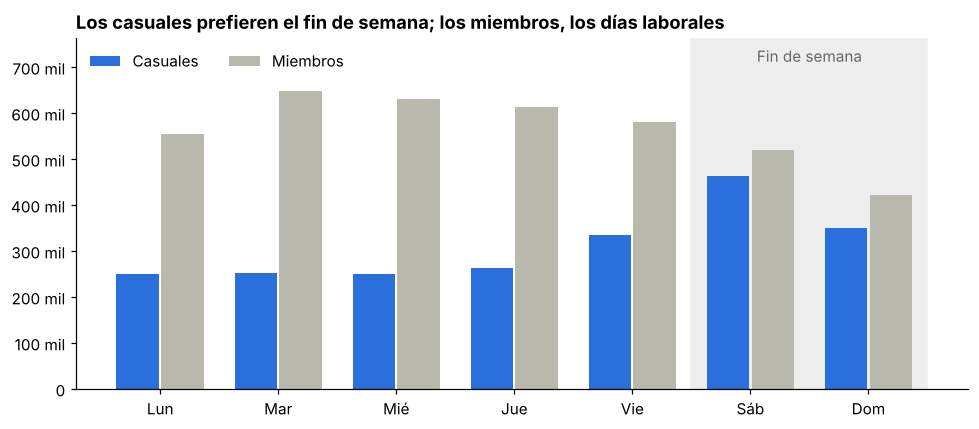

In [21]:
ORDEN_SEMANA = [2, 3, 4, 5, 6, 7, 1]  # lunes a domingo
viajes_dia = por_dia.pivot(index='day_of_week', columns='member_casual', values='viajes').loc[ORDEN_SEMANA]
posiciones = range(len(ORDEN_SEMANA))
ancho = 0.38

fig, ax = plt.subplots(figsize=(9, 4))
for k, tipo in enumerate(TIPOS):
    ax.bar([i + (k - 0.5) * ancho for i in posiciones], viajes_dia[tipo], width=ancho * 0.95,
           color=COLORES[tipo], label=ETIQUETAS[tipo])
tope = viajes_dia.to_numpy().max()
ax.axvspan(4.5, 6.5, color='#eeeeee', zorder=0)
ax.text(5.5, tope * 1.1, 'Fin de semana', ha='center', color='#666')
ax.set_xticks(list(posiciones), [DIAS[d] for d in ORDEN_SEMANA])
ax.set_ylim(0, tope * 1.18)
ax.yaxis.set_major_formatter(formato_miles)
ax.set_title('Los casuales prefieren el fin de semana; los miembros, los días laborales', loc='left')
ax.legend(frameon=False, ncol=2, loc='upper left')
guardar_grafico(fig, '1_viajes_por_dia.png')

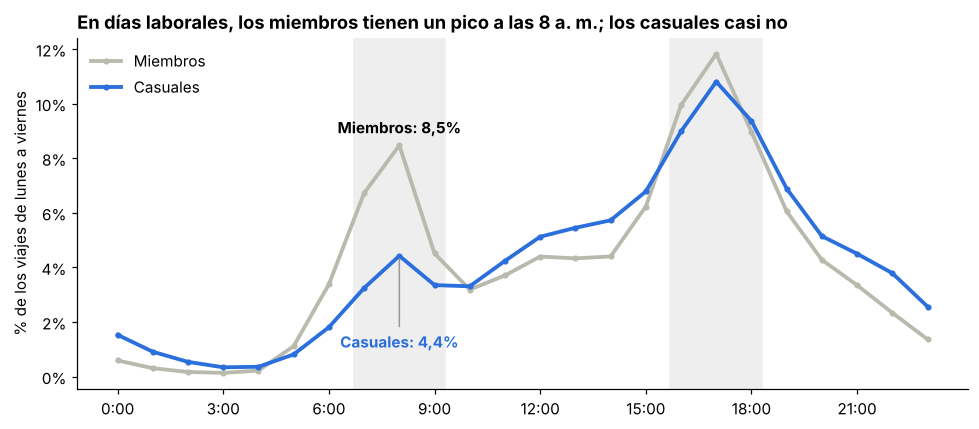

In [22]:
fig, ax = plt.subplots(figsize=(9, 4))
for tipo in ['member', 'casual']:
    ax.plot(hora.index, hora[tipo], marker='o', ms=3, lw=2.5, color=COLORES[tipo], label=ETIQUETAS[tipo])
for inicio, fin in [(7, 9), (16, 18)]:
    ax.axvspan(inicio - 0.3, fin + 0.3, color='#eeeeee', zorder=0)

ax.annotate(f"Miembros: {fmt_dec(hora.loc[8, 'member'])}%", (8, hora.loc[8, 'member']),
            xytext=(0, 8), textcoords='offset points', ha='center', weight='bold')
ax.annotate(f"Casuales: {fmt_dec(hora.loc[8, 'casual'])}%", (8, hora.loc[8, 'casual']),
            xytext=(0, -60), textcoords='offset points', ha='center', weight='bold', color=AZUL,
            arrowprops={'arrowstyle': '-', 'color': '#999'})
ax.set_xticks(range(0, 24, 3), [f'{h}:00' for h in range(0, 24, 3)])
ax.yaxis.set_major_formatter(formato_pct)
ax.set_ylabel('% de los viajes de lunes a viernes')
ax.set_title('En días laborales, los miembros tienen un pico a las 8 a. m.; los casuales casi no', loc='left')
ax.legend(frameon=False, loc='upper left')
guardar_grafico(fig, '2_viajes_por_hora.png')

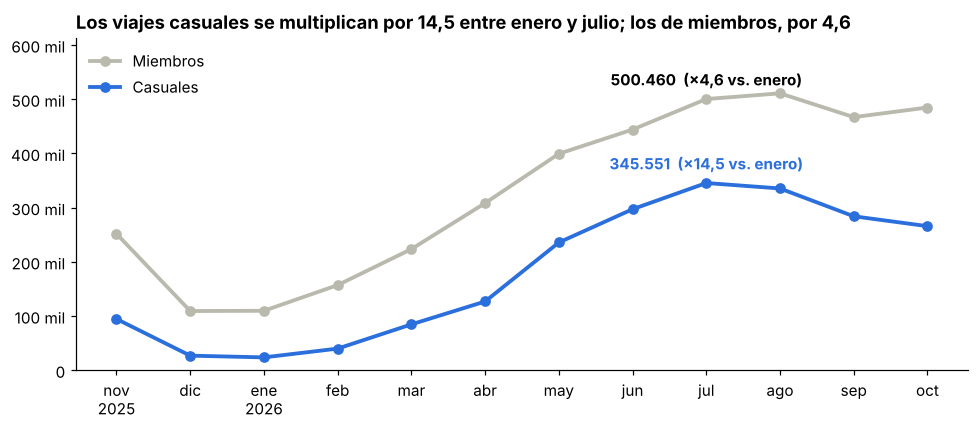

In [23]:
meses = list(mes.index)
etiquetas_mes = [f'{MESES[m.month - 1]}\n{m.year}' if m.month in (11, 1) else MESES[m.month - 1] for m in meses]

fig, ax = plt.subplots(figsize=(9, 4))
for tipo in ['member', 'casual']:
    ax.plot(range(len(meses)), mes[tipo], marker='o', lw=2.5, color=COLORES[tipo], label=ETIQUETAS[tipo])
    ax.annotate(f'{fmt_num(mes.loc[JULIO, tipo])}  (×{fmt_dec(crecimiento[tipo])} vs. enero)',
                (meses.index(JULIO), mes.loc[JULIO, tipo]), xytext=(0, 9), textcoords='offset points',
                ha='center', weight='bold', color=AZUL if tipo == 'casual' else 'black')
ax.set_xticks(range(len(meses)), etiquetas_mes)
ax.set_ylim(0, mes[TIPOS].to_numpy().max() * 1.2)
ax.yaxis.set_major_formatter(formato_miles)
ax.set_title(f"Los viajes casuales se multiplican por {fmt_dec(crecimiento['casual'])} entre enero y julio; "
             f"los de miembros, por {fmt_dec(crecimiento['member'])}", loc='left')
ax.legend(frameon=False, loc='upper left')
guardar_grafico(fig, '3_viajes_por_mes.png')

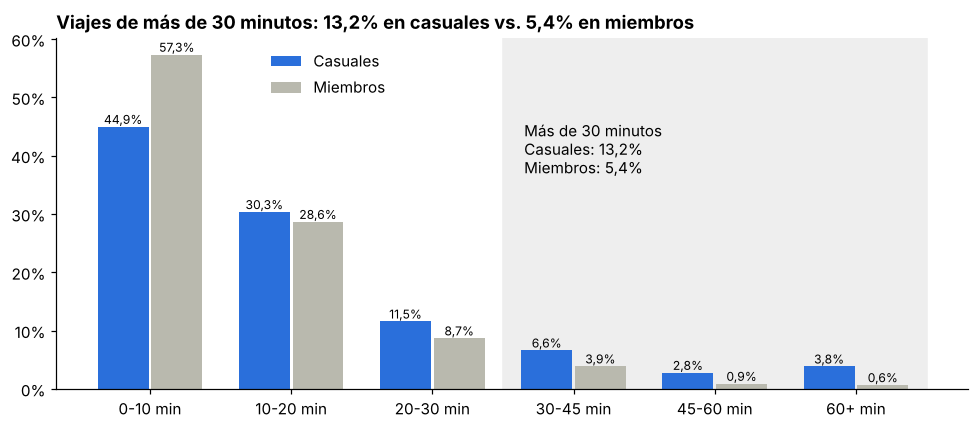

In [24]:
RANGOS = ['0-10', '10-20', '20-30', '30-45', '45-60', '60+']
RANGOS_LARGOS = ['30-45', '45-60', '60+']
duracion = sql('''
SELECT
    member_casual,
    CASE WHEN ride_length_min < 10 THEN '0-10'
         WHEN ride_length_min < 20 THEN '10-20'
         WHEN ride_length_min < 30 THEN '20-30'
         WHEN ride_length_min < 45 THEN '30-45'
         WHEN ride_length_min < 60 THEN '45-60'
         ELSE '60+' END AS rango,
    100.0 * COUNT(*) / SUM(COUNT(*)) OVER (PARTITION BY member_casual) AS pct
FROM viajes
GROUP BY member_casual, rango
''').pivot(index='rango', columns='member_casual', values='pct').loc[RANGOS]
largos = duracion.loc[RANGOS_LARGOS].sum()

fig, ax = plt.subplots(figsize=(9, 4))
for k, tipo in enumerate(TIPOS):
    barras = ax.bar([i + (k - 0.5) * ancho for i in range(len(RANGOS))], duracion[tipo], width=ancho * 0.95,
                    color=COLORES[tipo], label=ETIQUETAS[tipo])
    ax.bar_label(barras, labels=[f'{fmt_dec(v)}%' for v in duracion[tipo]], fontsize=8)
inicio_largos = RANGOS.index(RANGOS_LARGOS[0]) - 0.5
ax.axvspan(inicio_largos, len(RANGOS) - 0.5, color='#eeeeee', zorder=0)
ax.text(inicio_largos + 0.15, duracion.to_numpy().max() * 0.8,
        f"Más de 30 minutos\nCasuales: {fmt_dec(largos['casual'])}%\nMiembros: {fmt_dec(largos['member'])}%",
        va='top')
ax.set_xticks(range(len(RANGOS)), [f'{r} min' for r in RANGOS])
ax.yaxis.set_major_formatter(formato_pct)
ax.set_title(f"Viajes de más de 30 minutos: {fmt_dec(largos['casual'])}% en casuales "
             f"vs. {fmt_dec(largos['member'])}% en miembros", loc='left')
ax.legend(frameon=False, loc='upper left', bbox_to_anchor=(0.22, 1))
guardar_grafico(fig, '4_duracion.png')

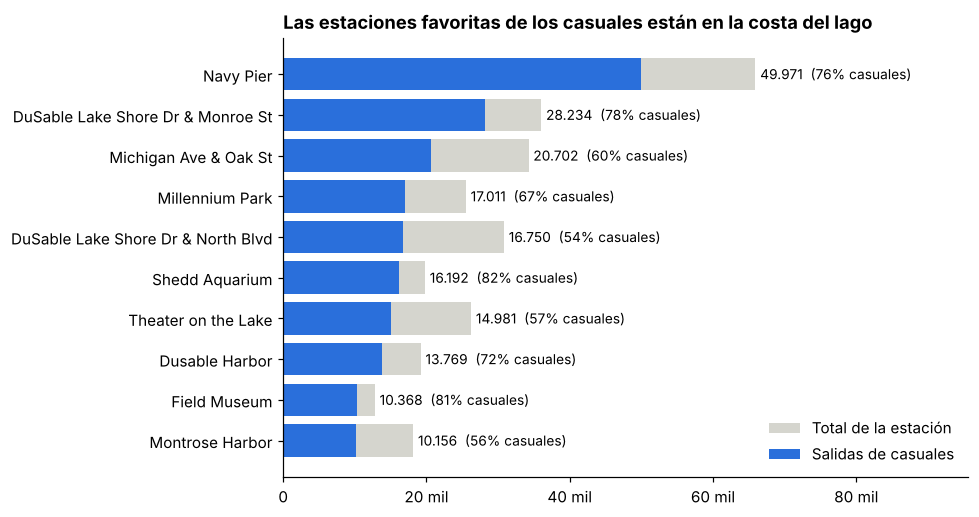

In [25]:
estaciones = sql('''
SELECT
    start_station_name AS estacion,
    COUNT(*) FILTER (WHERE member_casual = 'casual') AS casuales,
    COUNT(*) AS total
FROM viajes
WHERE start_station_name IS NOT NULL
GROUP BY estacion
ORDER BY casuales DESC
LIMIT 10
''').iloc[::-1]
estaciones['pct_casuales'] = 100 * estaciones['casuales'] / estaciones['total']

fig, ax = plt.subplots(figsize=(9, 4.8))
ax.barh(estaciones['estacion'], estaciones['total'], color=GRIS, alpha=0.6, label='Total de la estación')
ax.barh(estaciones['estacion'], estaciones['casuales'], color=AZUL, label='Salidas de casuales')
margen = estaciones['total'].max() * 0.01
for i, fila in enumerate(estaciones.itertuples()):
    ax.text(fila.total + margen, i, f'{fmt_num(fila.casuales)}  ({fila.pct_casuales:.0f}% casuales)',
            va='center', fontsize=9)
ax.xaxis.set_major_formatter(formato_miles)
ax.set_xlim(0, estaciones['total'].max() * 1.45)
ax.set_title('Las estaciones favoritas de los casuales están en la costa del lago', loc='left')
ax.legend(frameon=False, loc='lower right')
guardar_grafico(fig, '5_estaciones_casuales.png')

## 6. Act: conclusiones y recomendaciones

**Respuesta a la pregunta:** los miembros usan Cyclistic como transporte diario: viajes cortos, de lunes a viernes,
con picos a las 8 y a las 17 h y estable durante el año. Los casuales la usan sobre todo para pasear: viajes un 49%
más largos, más fines de semana, muy concentrados en verano y en estaciones turísticas junto al lago.

**Tres recomendaciones:**

1. **Convertir primero a los casuales que se trasladan al trabajo.** Hay 148.629 viajes casuales en la punta de la
   mañana, cortos y desde las mismas estaciones de oficinas que usan los miembros. Mostrarles el ahorro de una
   membresía después de varios viajes en horario punta.
2. **Campaña de primavera y verano en las estaciones del lago** (Navy Pier, DuSable Lake Shore Dr & Monroe St,
   Millennium Park, Shedd Aquarium), lanzada en abril y mayo, antes del peak de julio. Evaluar una membresía de
   temporada o de fin de semana como puerta de entrada.
3. **Mostrar el valor de la membresía en los viajes largos.** El 13,2% de los viajes casuales dura más de 30 minutos
   (5,4% en miembros): al terminar esos viajes, mostrar en la app cuánto costarían como miembro.

**Limitaciones:** el análisis cuenta viajes, no personas (no hay ID de usuario); la distancia es en línea recta;
el 20% de los viajes no tiene estación.

In [26]:
# Exportar las tablas resumen para análisis posteriores (paso 8 del enunciado)
resumen.to_csv(CARPETA_RESUMEN / 'resumen_miembros_vs_casuales.csv')
por_dia.to_csv(CARPETA_RESUMEN / 'viajes_por_dia.csv', index=False)
mes.to_csv(CARPETA_RESUMEN / 'viajes_por_mes.csv')
hora.to_csv(CARPETA_RESUMEN / 'viajes_por_hora_laborales.csv')
print('Archivos exportados:', sorted(p.name for p in CARPETA_RESUMEN.iterdir()))

Archivos exportados: ['resumen_miembros_vs_casuales.csv', 'viajes_por_dia.csv', 'viajes_por_hora_laborales.csv', 'viajes_por_mes.csv']
